# Analisis Sinyal Suara & Noise Statis
**Nama:** Romualdus Hary Prabowo
**NIM:** 123140083

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from scipy.signal import resample_poly
from math import gcd

# Memuat berkas audio asli dengan laju sampel bawaan (sr=None)
audio_path = "audio_original.wav"
y, sr = librosa.load(audio_path, sr=None)

# Menghitung durasi, total sampel, serta nilai amplitudo minimum dan maksimum
durasi = len(y) / sr
total_sampel = len(y)
amp_min = np.min(y)
amp_max = np.max(y)

# Mencetak hasil inspeksi awal
print(f"Durasi Rekaman       : {durasi:.2f} detik")
print(f"Laju Sampel Asli (fs): {sr} Hz")
print(f"Jumlah Sampel Total  : {total_sampel} sampel")
print(f"Amplitudo Minimum    : {amp_min:.4f}")
print(f"Amplitudo Maksimum   : {amp_max:.4f}")

/tmp/ipykernel_22439/76198192.py:11: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(audio_path, sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Durasi Rekaman       : 13.50 detik
Laju Sampel Asli (fs): 48000 Hz
Jumlah Sampel Total  : 648192 sampel
Amplitudo Minimum    : -0.3816
Amplitudo Maksimum   : 0.3775


### Analisis Inspeksi Awal
Rekaman audio memiliki laju sampel asli ($f_s$) sebesar 48000 Hz dengan durasi 13.50 detik, sehingga menghasilkan total 648192 sampel diskrit. Rentang nilai amplitudo berada di antara -0.3816 sampai 0.3775, yang menunjukkan sinyal terekam dengan baik tanpa mengalami distorsi pemotongan puncak (*clipping*) karena tidak melampaui batas skala penuh $[-1.0, 1.0]$.

Visualisasi Wavefrom

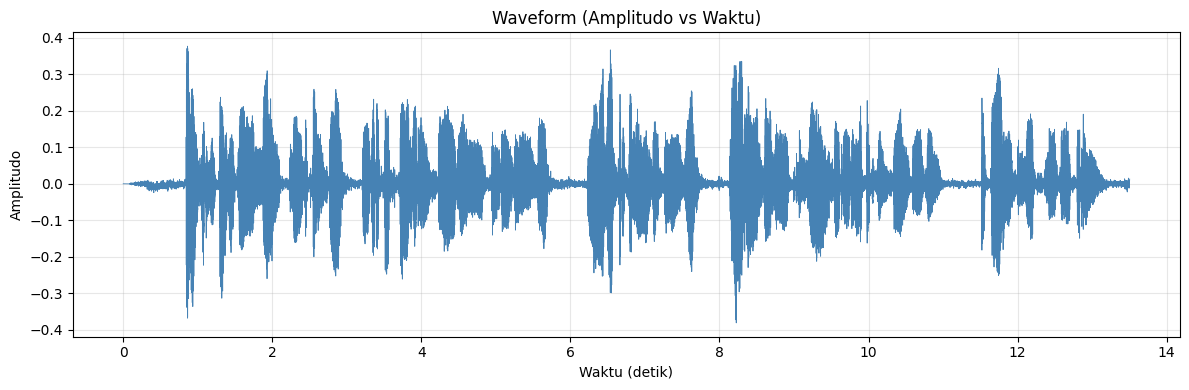

In [2]:
# Membuat sumbu waktu dalam satuan detik berdasarkan jumlah sampel dan laju sampel
waktu = np.linspace(0, durasi, total_sampel)

# Memvisualisasikan sinyal audio dalam domain waktu (Amplitudo vs Waktu)
plt.figure(figsize=(12, 4))
plt.plot(waktu, y, color='steelblue', linewidth=0.6)
plt.title("Waveform (Amplitudo vs Waktu)")
plt.xlabel("Waktu (detik)")
plt.ylabel("Amplitudo")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretasi Waveform (Amplitudo vs Waktu)
Pada grafik waveform, bagian vokal aktif terlihat dari lonjakan amplitudo dan gelombang yang lebih rapat, terutama pada detik 1–5,5, 6,2–7,6, 8,1–11,2, dan 11,6–13,2.

Sementara itu, bagian hening atau jeda terlihat dari amplitudo yang lebih kecil dan mendekati nol, seperti pada awal rekaman (0–1 detik), sekitar 5,5–6,2 detik, 7,6–8,1 detik, dan setelah 13,2 detik.

Pada bagian hening tersebut, gelombang tidak benar-benar mencapai nol, tetapi masih terdapat osilasi kecil. Hal ini menunjukkan adanya noise floor, yaitu derau latar belakang yang tetap terekam meskipun tidak ada suara utama.

Visualisasi Spektrum FFT

Frekuensi dominan pada spektrum: 308.72 Hz


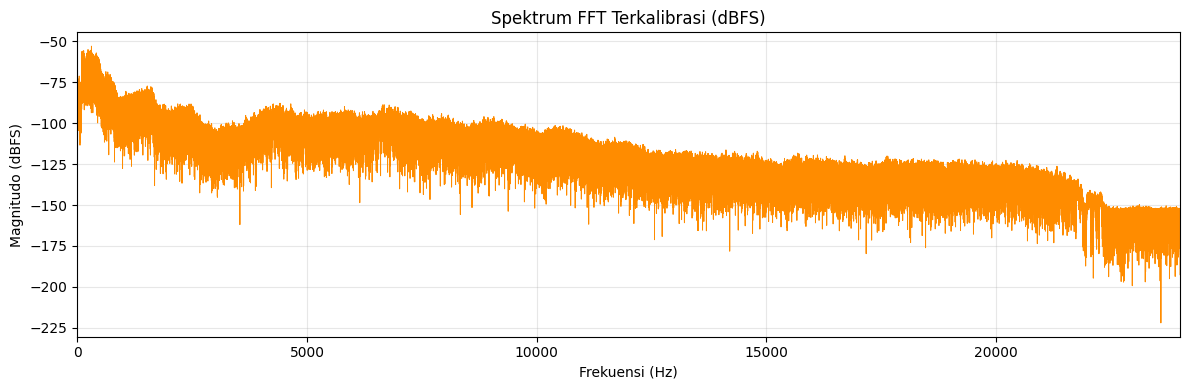

In [3]:
# Menghitung Fast Fourier Transform (FFT) satu sisi untuk sinyal bernilai riil
N = len(y)
fft_spectrum = np.fft.rfft(y)
frekuensi = np.fft.rfftfreq(N, d=1/sr)

# Menghitung magnitudo terkalibrasi dan mengonversinya ke skala desibel (dBFS)
magnitudo = np.abs(fft_spectrum) / N
magnitudo_dbfs = 20 * np.log10(np.maximum(magnitudo, 1e-12))

# Mencari titik frekuensi dengan energi tertinggi
frek_dominan = frekuensi[np.argmax(magnitudo_dbfs)]
print(f"Frekuensi dominan pada spektrum: {frek_dominan:.2f} Hz")

# Memvisualisasikan Spektrum FFT dalam skala dBFS
plt.figure(figsize=(12, 4))
plt.plot(frekuensi, magnitudo_dbfs, color='darkorange', linewidth=0.7)
plt.title("Spektrum FFT Terkalibrasi (dBFS)")
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Magnitudo (dBFS)")
plt.xlim(0, sr / 2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretasi Spektrum FFT (dBFS Terkalibrasi)
Berdasarkan grafik, energi sinyal paling kuat berada pada frekuensi rendah, dengan frekuensi dominan sekitar 308,72 Hz. Energi kemudian semakin menurun seiring meningkatnya frekuensi.

Suara vokal terutama tersebar pada sekitar 100–4.000 Hz, sedangkan di atas 5.000 Hz energi sinyal mulai lebih rendah dan terus meluruh. Hal ini menunjukkan bahwa rekaman didominasi oleh komponen frekuensi rendah hingga menengah, dengan energi frekuensi tinggi yang relatif kecil.

Visualisasi Spektrogram STFT

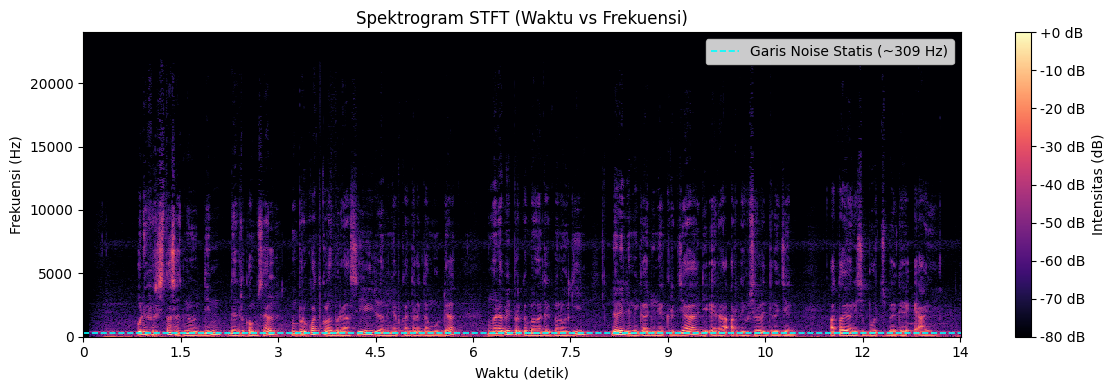

In [4]:
# Menghitung Short-Time Fourier Transform (STFT) dan konversi ke skala dB
n_fft = 2048
hop_length = 512
stft_matrix = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
stft_db = librosa.amplitude_to_db(np.abs(stft_matrix), ref=np.max)

# Memvisualisasikan Spektrogram STFT dan menandai area garis horizontal noise statis
plt.figure(figsize=(12, 4))
librosa.display.specshow(stft_db, sr=sr, hop_length=hop_length, x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format='%+2.0f dB', label='Intensitas (dB)')
plt.axhline(y=frek_dominan, color='cyan', linestyle='--', linewidth=1.2, label=f'Garis Noise Statis (~{frek_dominan:.0f} Hz)')
plt.title("Spektrogram STFT (Waktu vs Frekuensi)")
plt.xlabel("Waktu (detik)")
plt.ylabel("Frekuensi (Hz)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Interpretasi Spektrogram STFT
Derau statis terlihat jelas sebagai garis horizontal tipis di frekuensi rendah, tepat di sekitar 309 Hz (garis putus-putus biru muda). Garis ini menyala terus tanpa putus dari detik ke-0 sampai detik ke-14, tidak peduli ada suara atau tidak. Ini ciri khas noise stasioner: energinya konstan sepanjang waktu di frekuensi yang sama.

Sementara itu, suara pembaca berita muncul sebagai bercak - bercak vertikal berwarna ungu-oranye yang menjulang di atas garis noise tadi. Pola ini muncul putus-putus mengikuti ritme bicara.

Noise = garis datar konstan di bawah, suara manusia = bercak naik-turun yang berubah-ubah mengikuti pola bicara.

Visualisasi Mel-Spektrogram

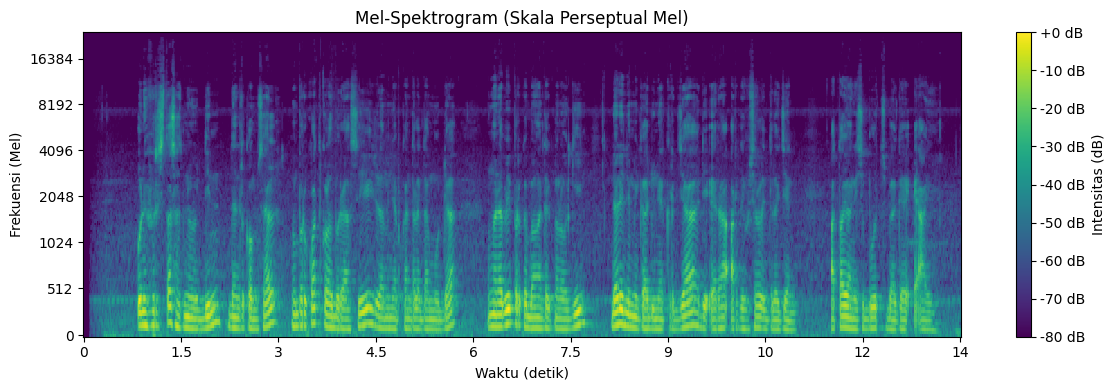

In [5]:
# Menghitung Mel-Spektrogram menggunakan 128 filterbank Mel dan konversi ke skala dB
mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=128)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

# Memvisualisasikan Mel-Spektrogram
plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_spec_db, sr=sr, hop_length=hop_length, x_axis='time', y_axis='mel', cmap='viridis')
plt.colorbar(format='%+2.0f dB', label='Intensitas (dB)')
plt.title("Mel-Spektrogram (Skala Perseptual Mel)")
plt.xlabel("Waktu (detik)")
plt.ylabel("Frekuensi (Mel)")
plt.tight_layout()
plt.show()

### Interpretasi Mel-Spektrogram
Mel-Spektrogram ini menggunakan skala frekuensi Mel, yang meniru cara telinga manusia mendengar, yaitu lebih detail di frekuensi rendah, lebih padat di frekuensi tinggi.

Karena itu, pita-pita formant (ciri khas suara manusia) yang di STFT biasa terlihat menumpuk tipis di bawah, di sini jadi lebih lebar dan jelas terpisah, terutama di rentang di bawah 2048 Hz. Warna kuning menandakan energi terkuat, terkonsentrasi di frekuensi rendah sesuai karakter suara manusia, sementara frekuensi tinggi tampak lebih gelap karena minim informasi ucapan.

Eksperimen Resampling & Pembuktian Aliasing

In [6]:
# Menentukan target laju sampel rendah (downsampling) dan faktor desimasi M
sr_target = 8000
M = int(round(sr / sr_target))
sr_naive = sr // M  # Laju sampel aktual hasil desimasi bulat

# Skenario A (Naive Decimation): Mengambil setiap sampel ke-M tanpa filter anti-aliasing
y_naive = y[::M]

# Skenario B (Resampling Standar): Menggunakan filter anti-aliasing LPF via resample_poly
faktor_gcd = gcd(sr, sr_naive)
up = sr_naive // faktor_gcd
down = sr // faktor_gcd
y_clean = resample_poly(y, up, down)

# Menyimpan kedua hasil eksperimen ke berkas .wav
sf.write("audio_downsampled_naive.wav", y_naive, sr_naive)
sf.write("audio_downsampled_clean.wav", y_clean, sr_naive)

print(f"Laju sampel awal  : {sr} Hz")
print(f"Faktor desimasi M : {M}")
print(f"Laju sampel baru  : {sr_naive} Hz (Batas Nyquist = {sr_naive / 2} Hz)")

Laju sampel awal  : 48000 Hz
Faktor desimasi M : 6
Laju sampel baru  : 8000 Hz (Batas Nyquist = 4000.0 Hz)


Komparasi Spektrogram Skenario A vs Skenario B

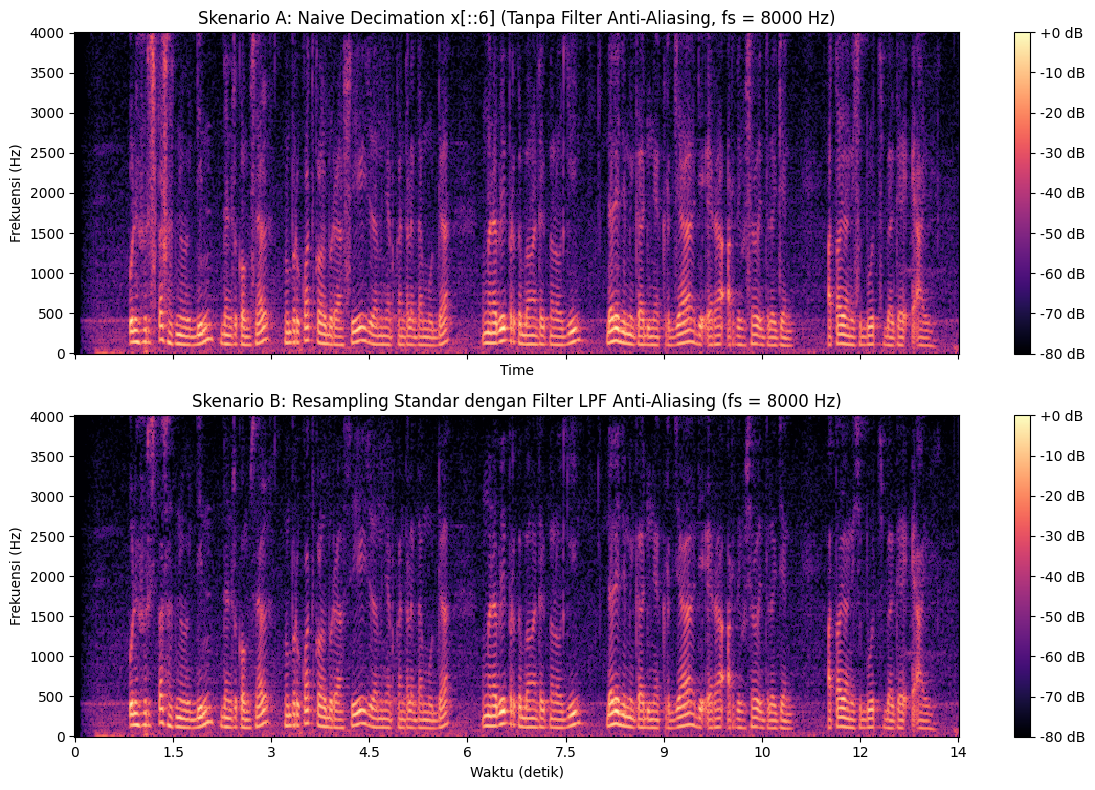

In [7]:
# Menghitung STFT untuk sinyal hasil Naive Decimation dan Resampling Standar
n_fft_low = 512
hop_low = 128

stft_naive_db = librosa.amplitude_to_db(np.abs(librosa.stft(y_naive, n_fft=n_fft_low, hop_length=hop_low)), ref=np.max)
stft_clean_db = librosa.amplitude_to_db(np.abs(librosa.stft(y_clean, n_fft=n_fft_low, hop_length=hop_low)), ref=np.max)

# Memvisualisasikan perbandingan kedua spektrogram secara berdampingan
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, sharey=True)

# Plot Skenario A (Naive Decimation)
img1 = librosa.display.specshow(stft_naive_db, sr=sr_naive, hop_length=hop_low, x_axis='time', y_axis='hz', ax=axes[0], cmap='magma')
axes[0].set_title(f"Skenario A: Naive Decimation x[::{M}] (Tanpa Filter Anti-Aliasing, fs = {sr_naive} Hz)")
axes[0].set_ylabel("Frekuensi (Hz)")
fig.colorbar(img1, ax=axes[0], format='%+2.0f dB')

# Plot Skenario B (Resampling Standar)
img2 = librosa.display.specshow(stft_clean_db, sr=sr_naive, hop_length=hop_low, x_axis='time', y_axis='hz', ax=axes[1], cmap='magma')
axes[1].set_title(f"Skenario B: Resampling Standar dengan Filter LPF Anti-Aliasing (fs = {sr_naive} Hz)")
axes[1].set_xlabel("Waktu (detik)")
axes[1].set_ylabel("Frekuensi (Hz)")
fig.colorbar(img2, ax=axes[1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

Analisis Komparasi Aliasing & Rangkuman Mandiri

### Analisis Komparasi Spektrogram & Pembuktian Aliasing
Perbedaan yang tampak:

Pada Skenario A (naive decimation x[::6]), noise floor pada pita frekuensi tinggi (>2000 Hz) terlihat jauh lebih kotor/hazy dibanding Skenario B warna ungu-magenta tersebar merata di seluruh rentang frekuensi, bukan hanya di sekitar harmonik sinyal. Ini adalah tanda klasik aliasing: komponen frekuensi asli yang sebenarnya berada di atas Nyquist baru (fs/2 = 4000 Hz) terlipat balik (fold-back) ke pita frekuensi rendah-menengah, menambah energi palsu yang bercampur dengan noise asli sinyal.

Pada Skenario B (resampling dengan filter LPF anti-aliasing), latar belakangnya jauh lebih gelap/bersih terutama di atas 2000 Hz. Struktur harmonik utama (garis-garis melengkung di bawah 1500 Hz) tetap terjaga dan justru terlihat lebih tegas karena tidak tertutup oleh energi hasil lipatan.

Penjelasan teknis singkat:

Sinyal asli punya bandwidth yang melebihi fs_baru/2. Decimation langsung (ambil tiap sampel ke-6) tanpa filter LPF sebelumnya melanggar syarat Nyquist, semua komponen frekuensi di atas 4000 Hz tidak dibuang, melainkan terlipat masuk ke rentang 0–4000 Hz dengan pola cermin (mirror-fold). Filter anti-aliasing pada Skenario B memotong komponen tersebut sebelum proses downsampling, sehingga tidak ada yang bisa terlipat.

Rangkuman Mandiri

Perbandingan ini membuktikan pentingnya filter anti-aliasing sebelum downsampling. Tanpa filter tersebut (Skenario A), sinyal hasil decimation mengandung distorsi berupa energi frekuensi tinggi yang salah tempat (aliasing), terlihat sebagai noise tambahan yang menyebar di seluruh spektrogram. Dengan filter LPF (Skenario B), integritas spektral sinyal terjaga, hanya frekuensi yang memang valid pada fs baru yang muncul, menghasilkan representasi yang lebih akurat dan bebas artefak.